In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
%cd /content/drive/MyDrive/flowers prediction/flowers

/content/drive/MyDrive/flowers prediction/flowers


In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Input,
    Rescaling,
    Conv2D,
    MaxPooling2D,
    Flatten,
    Dense,
    Dropout
)

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

print("TensorFlow version:", tf.__version__)


TensorFlow version: 2.21.0


In [ ]:
dataset_dir = "/content/drive/MyDrive/flowers prediction/flowers"
print("Dataset path:", os.path.abspath(dataset_dir))
print("Contents:", os.listdir(dataset_dir))


Dataset path: /content/drive/MyDrive/flowers prediction/flowers
Contents: ['rose', 'dandelion', 'daisy']


Number of daisy images: 257
Number of dandelion images: 698
Number of rose images: 144
Total images: 1099


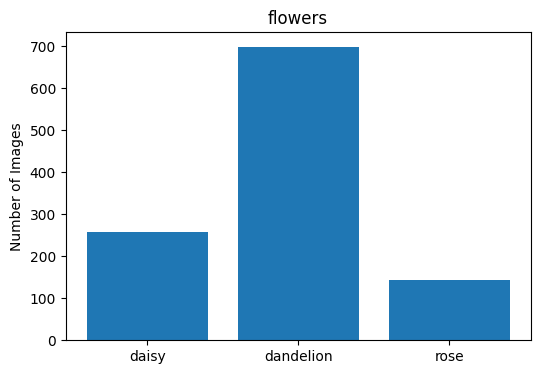

In [ ]:
daisy_dir = os.path.join(dataset_dir, "daisy")
dandelion_dir = os.path.join(dataset_dir, "dandelion")
rose_dir = os.path.join(dataset_dir, "rose")


daisy_count = len([
    f for f in os.listdir(daisy_dir)
    if os.path.isfile(os.path.join("/content/drive/MyDrive/flowers prediction/flowers/daisy", f))
])

dandelion_count = len([
    f for f in os.listdir(dandelion_dir)
    if os.path.isfile(os.path.join("/content/drive/MyDrive/flowers prediction/flowers/dandelion", f))
])

rose_count = len([
    f for f in os.listdir(rose_dir)
    if os.path.isfile(os.path.join("/content/drive/MyDrive/flowers prediction/flowers/rose", f))
])

print("Number of daisy images:", daisy_count)
print("Number of dandelion images:", dandelion_count)
print("Number of rose images:",rose_count)
print("Total images:", daisy_count + dandelion_count + rose_count)

plt.figure(figsize=(6, 4))
plt.bar(["daisy", "dandelion","rose"], [daisy_count, dandelion_count,rose_count])
plt.ylabel("Number of Images")
plt.title("flowers")
plt.show()


In [ ]:
import os

for folder in os.listdir(dataset_dir):
    folder_path = os.path.join(dataset_dir, folder)

    print("\nFolder:", folder)

    for root, dirs, files in os.walk(folder_path):
        print("Location:", root)
        print("Files:", len(files))
        print("Sample:", files[:5])


Folder: rose
Location: /content/drive/MyDrive/flowers prediction/flowers/rose
Files: 144
Sample: ['10090824183_d02c613f10_m.jpg', '102501987_3cdb8e5394_n.jpg', '10503217854_e66a804309.jpg', '10894627425_ec76bbc757_n.jpg', '110472418_87b6a3aa98_m.jpg']

Folder: dandelion
Location: /content/drive/MyDrive/flowers prediction/flowers/dandelion
Files: 698
Sample: ['8744249948_36cb1969f8_m.jpg', '8756906129_b05a1b26f2.jpg', '8754822932_948afc7cef.jpg', '8963359346_65ca69c59d_n.jpg', '8935477500_89f22cca03_n.jpg']

Folder: daisy
Location: /content/drive/MyDrive/flowers prediction/flowers/daisy
Files: 257
Sample: ['799952628_bf836677fa_n.jpg', '705422469_ffa28c566d.jpg', '813445367_187ecf080a_n.jpg', '99306615_739eb94b9e_m.jpg', '5881907044_92a85a05c8_n.jpg']


In [ ]:
IMG_SIZE = (128, 128)
BATCH_SIZE = 32
SEED = 42

print("Image size:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)


Image size: (128, 128)
Batch size: 32


In [ ]:
from PIL import Image
import os
import tensorflow as tf

# --- Step 1: Forcefully convert or clean all images to 3-channel RGB ---
print("Actively scanning and standardizing dataset to RGB mode...")
for root, dirs, files in os.walk(dataset_dir):
    for file in files:
        if file.lower().endswith(('.png', '.jpg', '.jpeg')):
            file_path = os.path.join(root, file)
            try:
                # Open, load, and convert to standard RGB mode
                with Image.open(file_path) as img:
                    rgb_img = img.convert('RGB')
                    # Save it back to replace any corrupt/irregular format
                    rgb_img.save(file_path, "JPEG")
            except Exception as e:
                print(f"Removing corrupted/unreadable image: {file_path}. Error: {e}")
                try:
                    os.remove(file_path)
                except:
                    pass

print("Cleanup complete. Re-loading datasets...")


Actively scanning and standardizing dataset to RGB mode...
Cleanup complete. Re-loading datasets...


In [ ]:
# Step 2: Load the dataset

train_dataset = tf.keras.utils.image_dataset_from_directory(
    dataset_dir,
    validation_split=0.20,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical",
    color_mode="rgb",
    shuffle=True
)

test_dataset = tf.keras.utils.image_dataset_from_directory(
    dataset_dir,
    validation_split=0.20,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical",
    color_mode="rgb",
    shuffle=False
)

# Step 3: Performance optimization

AUTOTUNE = tf.data.AUTOTUNE

train_dataset = train_dataset.cache().shuffle(1000).prefetch(
    buffer_size=AUTOTUNE
)

test_dataset = test_dataset.cache().prefetch(
    buffer_size=AUTOTUNE
)


Found 1099 files belonging to 3 classes.
Using 880 files for training.
Found 1099 files belonging to 3 classes.
Using 219 files for validation.


In [ ]:
class_names = ['daisy', 'dandelion', 'rose']

print("Class names:", class_names)

for index, name in enumerate(class_names):
    print(index, "->", name)


Class names: ['daisy', 'dandelion', 'rose']
0 -> daisy
1 -> dandelion
2 -> rose


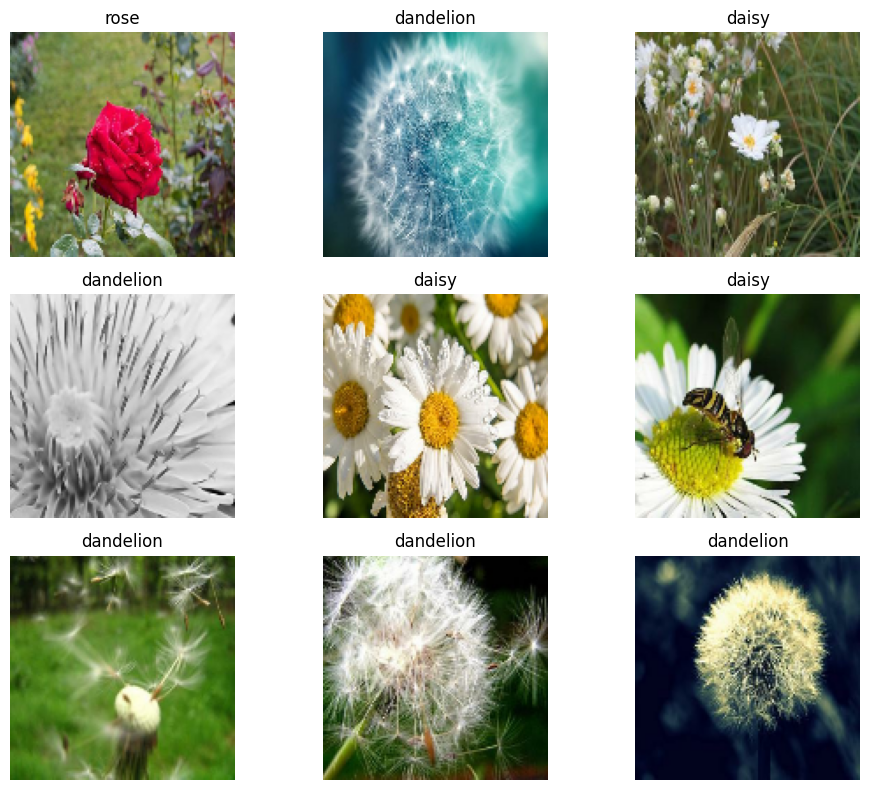

In [ ]:
plt.figure(figsize=(10, 8))

for images, labels in train_dataset.take(1):
    for i in range(min(9, len(images))):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))

        label = np.argmax(labels[i].numpy())
        plt.title(class_names[label])
        plt.axis("off")

plt.tight_layout()
plt.show()


In [ ]:
AUTOTUNE = tf.data.AUTOTUNE

train_dataset = train_dataset.cache().shuffle(1000).prefetch(
    buffer_size=AUTOTUNE
)

test_dataset = test_dataset.cache().prefetch(
    buffer_size=AUTOTUNE
)


In [ ]:
model = Sequential([
    Input(shape=(128, 128, 3)),

    # Normalize pixel values: 0-255 -> 0-1
    Rescaling(1.0 / 255),

    # Convolution Block 1
    Conv2D(32, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    # Convolution Block 2
    Conv2D(64, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    # Convolution Block 3
    Conv2D(128, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    # Classification section
    Flatten(),
    Dense(128, activation="relu"),
    Dropout(0.5),

    # Binary output
    Dense(3, activation="softmax")
])

model.summary()


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_2 (Rescaling)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,305,027 (12.61 MB)

 Trainable params: 3,305,027 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully.")


Model compiled successfully.


In [ ]:
print("Number of classes:", len(class_names))

for images, labels in train_dataset.take(1):
    print("Image shape:", images.shape)
    print("Label shape:", labels.shape)

print("Model output shape:", model.output_shape)

Number of classes: 3
Image shape: (32, 128, 128, 3)
Label shape: (32, 3)
Model output shape: (None, 3)


In [ ]:
EPOCHS = 10

history = model.fit(
    train_dataset,
    epochs=EPOCHS,
    validation_data=test_dataset
)

Epoch 1/10
28/28 ━━━━━━━━━━━━━━━━━━━━ 20s 662ms/step - accuracy: 0.5591 - loss: 0.6009 - val_accuracy: 0.4521 - val_loss: 0.6931
Epoch 2/10
28/28 ━━━━━━━━━━━━━━━━━━━━ 20s 634ms/step - accuracy: 0.6648 - loss: 0.4840 - val_accuracy: 0.5342 - val_loss: 0.6616
Epoch 3/10
28/28 ━━━━━━━━━━━━━━━━━━━━ 20s 601ms/step - accuracy: 0.7364 - loss: 0.4238 - val_accuracy: 0.8219 - val_loss: 0.3085
Epoch 4/10
28/28 ━━━━━━━━━━━━━━━━━━━━ 18s 632ms/step - accuracy: 0.7818 - loss: 0.3708 - val_accuracy: 0.7717 - val_loss: 0.3509
Epoch 5/10
28/28 ━━━━━━━━━━━━━━━━━━━━ 17s 599ms/step - accuracy: 0.8136 - loss: 0.3255 - val_accuracy: 0.7352 - val_loss: 0.3946
Epoch 6/10
28/28 ━━━━━━━━━━━━━━━━━━━━ 17s 601ms/step - accuracy: 0.8386 - loss: 0.3090 - val_accuracy: 0.7854 - val_loss: 0.3285
Epoch 7/10
28/28 ━━━━━━━━━━━━━━━━━━━━ 20s 609ms/step - accuracy: 0.8432 - loss: 0.2932 - val_accuracy: 0.7808 - val_loss: 0.3368
Epoch 8/10
28/28 ━━━━━━━━━━━━━━━━━━━━ 17s 598ms/step - accuracy: 0.8636 - loss: 0.2483 - val_accu

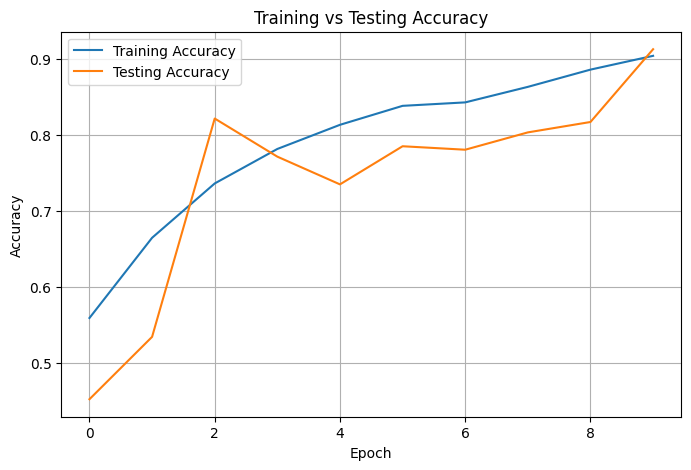

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Testing Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Testing Accuracy")
plt.legend()
plt.grid(True)
plt.show()


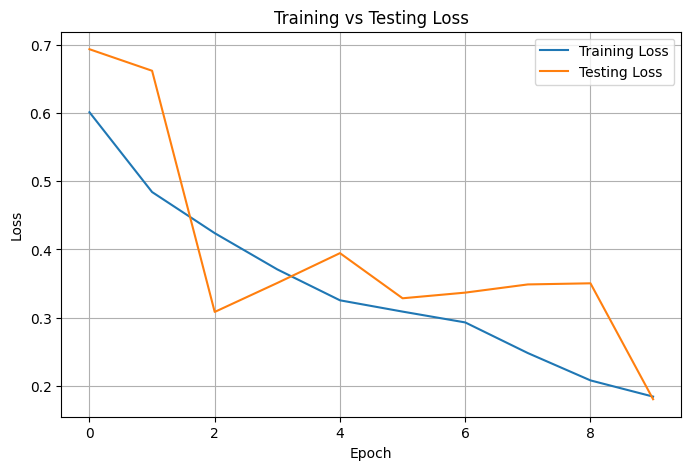

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Testing Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Testing Loss")
plt.legend()
plt.grid(True)
plt.show()


In [ ]:
test_loss, test_accuracy = model.evaluate(test_dataset)

print("Test Loss     :", test_loss)
print("Test Accuracy :", f"{test_accuracy * 100:.2f}%")


7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 197ms/step - accuracy: 0.9132 - loss: 0.1807
Test Loss     : 0.1807297319173813
Test Accuracy : 91.32%


In [ ]:
y_true = []
y_probability = []

for images, labels in test_dataset:
    probabilities = model.predict(images, verbose=0).ravel()

    y_probability.extend(probabilities)
    y_true.extend(labels.numpy().astype(int))

y_true = np.array(y_true)
y_probability = np.array(y_probability)

y_pred = (y_probability >= 0.5).astype(int)

print("Number of test images:", len(y_true))


Number of test images: 219


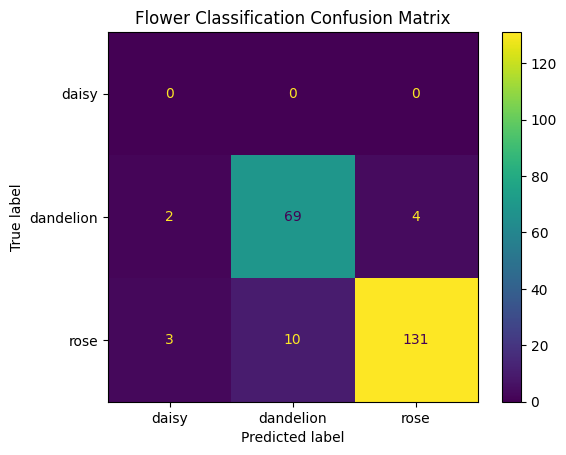

In [ ]:
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

y_true = []
y_pred = []

for images, labels in test_dataset:
    predictions = model.predict(images, verbose=0)

    y_true.extend(np.argmax(labels.numpy(), axis=1))
    y_pred.extend(np.argmax(predictions, axis=1))

cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot()
plt.title("Flower Classification Confusion Matrix")
plt.show()

In [ ]:
print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_names
    )
)


              precision    recall  f1-score   support

       daisy       0.00      0.00      0.00         0
   dandelion       0.87      0.92      0.90        75
        rose       0.97      0.91      0.94       144

    accuracy                           0.91       219
   macro avg       0.61      0.61      0.61       219
weighted avg       0.94      0.91      0.92       219



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Prediction : daisy
Confidence : 99.72%


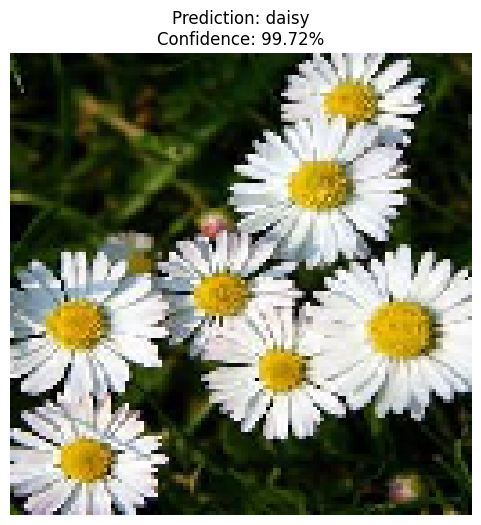

In [ ]:
from tensorflow.keras.utils import load_img, img_to_array

# CHANGE THIS PATH to your image
image_path = "/content/drive/MyDrive/flowers prediction/flowers/daisy/144076848_57e1d662e3_m.jpg"

if not os.path.exists(image_path):
    print("Image not found.")
    print("Change image_path to the location of your test image.")
else:
    img = load_img(
        image_path,
        target_size=IMG_SIZE
    )

    img_array = img_to_array(img)
    img_array = img_array / 255.0
    img_array = np.expand_dims(img_array, axis=0)

    probability = model.predict(
        img_array,
        verbose=0
    )[0][0]

    # 0 = daisy, 1 = rose
    if probability >= 0.5:
        predicted_class = "rose"
        confidence = probability
    else:
        predicted_class = "daisy"
        confidence = 1 - probability

    print("Prediction :", predicted_class)
    print("Confidence :", f"{confidence * 100:.2f}%")

    plt.figure(figsize=(6, 6))
    plt.imshow(img)
    plt.title(
        f"Prediction: {predicted_class}\n"
        f"Confidence: {confidence * 100:.2f}%"
    )
    plt.axis("off")
    plt.show()


In [ ]:
model.save("flowers classification_cnn.keras")

print("Model saved as: flowers classification_cnn.keras")


Model saved as: flowers classification_cnn.keras
